# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-06-16 10:17:54,220:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-06-16 10:17:54,220 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-06-16 10:17:54,413 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux

import skewerjax.optical_depth.line_profile as lp
import skewerjax.optical_depth.optical_depth as od
import skewerjax.optical_depth.analytic_solutions as analytic_solutions

from skewerjax.constants.physical_constants import phys
from skewerjax.optical_depth.voigt import Gaussian

# Auxiliary objects that would be employed throughout the notebook

### Define radiation domination cosmology to employ in the different examples that require it

In [3]:
# Create cosmology object
cosmology = Cosmology(
    H0=phys.H0, Omega_r_0=1.0, Omega_m_0=0.0, Omega_k_0=0.0, Omega_lambda_0=0.0,
)
# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time
ii_cosmology = 0

### Define lines to study

In [4]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyB", "SiIII-1206"])
line_bundle_null = sjx.constants.lines.LineBundle(["nullHI-LyA", "nullHI-LyB", "nullSiIII1206"])

### Auxiliary variables

In [5]:
T0_tiny = jnp.finfo(jnp.dtype('float32')).tiny

T0_min = 1e4
T0_max = 1e8

n0_min = 1e-9
n0_max = 1e-3
n0_ref = 1e-7

L_box_Kpc      = 1e-3 # in Mpc
L_box_five_Mpc = 5    # in Mpc

# Validation with $T=0,\, v_{LoS}=0, \, n=n_0, a(x) = 1.0, a_0 = 1.0$

In [6]:
# Define the fields to sample

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_Kpc)),     # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min, n0_max, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_Kpc)),     # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min, n0_max, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    }
})

# Define skewers

N_sk = 7
N_ppsk = 32

_points        = aux.make_plane_points(L_box_Kpc, 'x', L_box_Kpc/2, N_sk, N_ppsk)
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    manual_scale_factors=jnp.ones_like(_points[None, ..., 0]), # if provided, must have shape (N_cosmologies, N_skewers, N_points_per_skewer)
)

2026-06-16 10:17:57,760 - INFO - Initializing SkewerBundle with 7 skewers, 32 points per skewer
2026-06-16 10:17:57,820 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 7 skewers
2026-06-16 10:17:57,841 - INFO - All skewers set to absorption mode
2026-06-16 10:17:57,913 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-16 10:17:58,203 - INFO - Computing comoving distances along skewer direction
2026-06-16 10:17:58,390 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-06-16 10:17:58,390 - INFO - Storing quadri-vectors
2026-06-16 10:17:58,432 - INFO - SkewerBundle initialization complete


In [7]:
velocities_kms = jnp.linspace(-200, 200, 1024)

a_dagger = jnp.ones_like(skewer_bundle.scale_factors[0])

tau = od.OpticalDepthCalculator(
    skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
)
tau.compute()
optical_depth = tau.optical_depth
F_over_F0 = jnp.exp(-optical_depth)

2026-06-16 10:17:58,932 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=3, N_species=2, N_sk=7, N_ppsk=32, N_v=1024.
2026-06-16 10:17:58,933 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 0.958 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.8%
  System RAM  : used=23.963 GB, available=101.644 GB  [█████░░░░░░░░░░░░░░░░░░░░░░░]  19.1%
  Change      : ΔRSS=first checkpoint
2026-06-16 10:17:58,933 - INFO - [OPTICAL_DEPTH] start: ii_cosmology=0, voigt=ExoJAX
2026-06-16 10:17:58,946 - INFO - 
[OPTICAL_DEPTH][MEM] loaded quadri_vectors
  Process RSS : 0.960 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.8%
  System RAM  : used=23.960 GB, available=101.647 GB  [█████░░░░░░░░░░░░░░░░░░░░░░░]  19.1%
  Change      : ΔRSS=+0.002 GB
  Array       : shape=(7, 32, 4), dtype=float32, nbytes=0.000 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.0%
2026-06-16 10:18:00,359 - INFO - 
[OPTICAL_DEPTH][MEM] after compute_line_profiles
  Process RSS : 1.062 / 125.607 GB  [░░░░░░░░░░░░░░░

In [8]:
# ------------------------------------------------------------------
# Analytical result in velocity units
# ------------------------------------------------------------------

quadri_vectors_analytic = jnp.array([
    jnp.ones(N_sk) * skewer_bundle.a0[0],
    jnp.ones(N_sk) * L_box_Kpc / 2,
    jnp.linspace(0, L_box_Kpc, N_sk),
    jnp.ones(N_sk) * L_box_Kpc / 2,
]).T

indices_for_species = {
    sp: line_bundle.indices_for_species(sp)
    for sp in line_bundle.species_keys
}

sampled_number_densities_cm3 = fields.tile_field_to_lines(
    "number_density",
    quadri_vectors_analytic,
    indices_for_species=indices_for_species,
)  # (N_lines, N_sk)

# In this test a_dagger = 1 and a_obs = 1.
# Use scalar values for the analytical wavelength conversion.
wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
    velocities_kms,
    line_bundle,
    a_dagger=1.0,
    a_obs=1.0,
)  # (N_lines, N_v)

optical_depth_analytic_list = []

for i_line in range(line_bundle.n_lines):
    _tau_i = analytic_solutions.compute_optical_depth_analytical_static_Natural(
        wavelengths_per_line_A[i_line],
        line_bundle.lambda0_A[i_line:i_line + 1],
        line_bundle.A21_GHz[i_line:i_line + 1],
        line_bundle.f_osc[i_line:i_line + 1],
        skewer_bundle.a0,
        L_box_Kpc * jnp.ones(len(skewer_bundle.a0)),
        sampled_number_densities_cm3[i_line],
    )  # (1, N_sk, N_v)

    optical_depth_analytic_list.append(_tau_i[0])

optical_depth_analytic = jnp.stack(optical_depth_analytic_list, axis=0)  # (N_lines, N_sk, N_v)
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

/home/dlopez/tmp/pip-tmp/ipykernel_464601/986450936.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])
/home/dlopez/tmp/pip-tmp/ipykernel_464601/986450936.py:49: RuntimeWarning: invalid value encountered in divide
  residual = F_over_F0_np[i_line, i_sk] / F_over_F0_analytic_np[i_line, i_sk] - 1.0
/home/dlopez/tmp/pip-tmp/ipykernel_464601/986450936.py:49: RuntimeWarning: divide by zero encountered in divide
  residual = F_over_F0_np[i_line, i_sk] / F_over_F0_analytic_np[i_line, i_sk] - 1.0


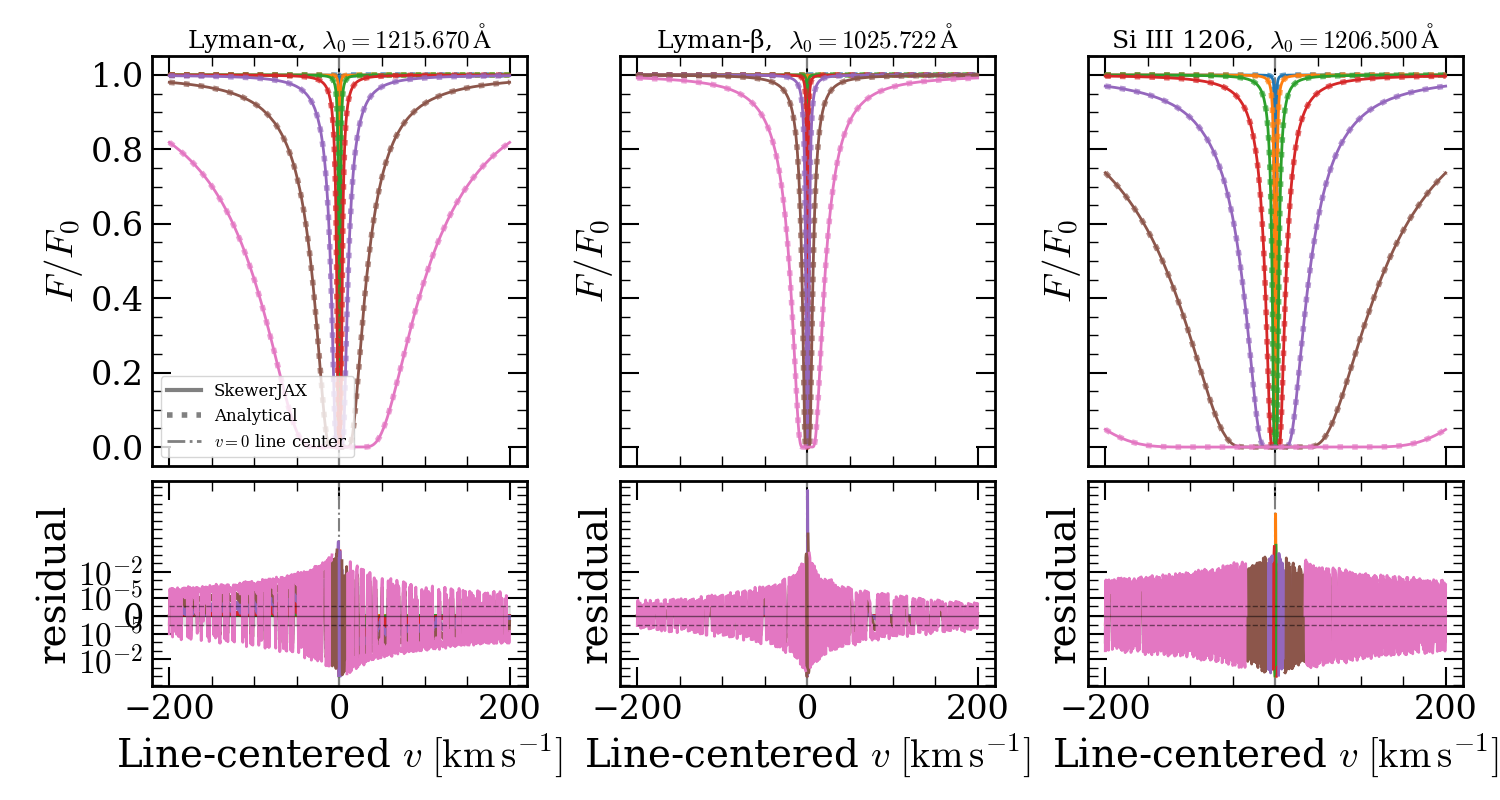

In [9]:
# ------------------------------------------------------------------
# Plot numerical vs analytical result in velocity units
# ------------------------------------------------------------------

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

velocities_np = np.asarray(velocities_kms)
F_over_F0_np = np.asarray(F_over_F0)
F_over_F0_analytic_np = np.asarray(F_over_F0_analytic)

N_lines = line_bundle.n_lines
N_sk = F_over_F0_np.shape[1]

fig, axes = plt.subplots(
    nrows=2,
    ncols=N_lines,
    figsize=(5.0 * N_lines, 8),
    sharex=True,
    sharey="row",
    gridspec_kw=dict(height_ratios=[2, 1]),
)

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_line, (ax_flux, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):

    ax_flux.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        ax_flux.plot(
            velocities_np,
            F_over_F0_np[i_line, i_sk],
            color=colors[i_sk],
            linestyle="-",
            linewidth=2.0,
        )

        ax_flux.plot(
            velocities_np,
            F_over_F0_analytic_np[i_line, i_sk],
            color=colors[i_sk],
            linestyle=":",
            linewidth=4.0,
            alpha=0.7,
        )

        residual = F_over_F0_np[i_line, i_sk] / F_over_F0_analytic_np[i_line, i_sk] - 1.0

        ax_res.plot(
            velocities_np,
            residual,
            color=colors[i_sk],
            linestyle="-",
            linewidth=2.0,
        )

    ax_flux.set_title(
        rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$",
        fontsize=18,
    )

    ax_flux.set_ylabel(r"$F/F_0$")
    ax_res.set_xlabel(r"Line-centered $v\;[\mathrm{km\,s^{-1}}]$")
    ax_res.set_ylabel("residual")

    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(velocities_np, -1e-6, 1e-6, color="grey", alpha=0.2)
    ax_res.hlines(1e-6, xmin=velocities_np[0], xmax=velocities_np[-1], color="k", linewidth=1, linestyle="--", alpha=0.5)
    ax_res.hlines(-1e-6, xmin=velocities_np[0], xmax=velocities_np[-1], color="k", linewidth=1, linestyle="--", alpha=0.5)

    ax_res.set_yscale("symlog", linthresh=1e-6)
    ax_res.set_yticks([-1e-2, -1e-5, 0.0, 1e-5, 1e-2])
    ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

handles = [
    Line2D([0], [0], color="grey", lw=3, linestyle="-", label="SkewerJAX"),
    Line2D([0], [0], color="grey", lw=4, linestyle=":", label="Analytical"),
    Line2D([0], [0], color="grey", lw=2, linestyle="-.", label=r"$v=0$ line center"),
]

axes[0, 0].legend(handles=handles, loc="lower left", fontsize=12, frameon=True)

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.25)

plt.show()

# Validation with $A_{j} = 0,\, v_{LoS}=0, \, n=n_0, T = T_0, a(x) = 1.0, a_0 = 1.0$

In [10]:
# Define the fields to sample

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_Kpc)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_Kpc)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_Kpc)),                   # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_Kpc)), # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                        # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                       # UNITS: [GHz]
    }
})

# Define skewers

N_sk = 5
N_ppsk = 32

_points = aux.make_plane_points(L_box_Kpc, 'y', L_box_Kpc/2, N_sk, N_ppsk)
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    manual_scale_factors=jnp.ones_like(_points[None, ..., 0]),
)

# Define velocity grid

velocities_kms = jnp.linspace(-3000.0, 3000.0, 1024)
a_dagger = jnp.ones_like(skewer_bundle.scale_factors[0])

# Compute optical depth in velocity units

tau = od.OpticalDepthCalculator(
    skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
)
tau.compute()
optical_depth = tau.optical_depth

F_over_F0 = jnp.exp(-optical_depth)

2026-06-16 10:18:05,794 - INFO - Initializing SkewerBundle with 5 skewers, 32 points per skewer
2026-06-16 10:18:05,812 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 5 skewers
2026-06-16 10:18:05,829 - INFO - All skewers set to absorption mode
2026-06-16 10:18:05,898 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-16 10:18:06,155 - INFO - Computing comoving distances along skewer direction
2026-06-16 10:18:06,340 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-06-16 10:18:06,340 - INFO - Storing quadri-vectors
2026-06-16 10:18:06,384 - INFO - SkewerBundle initialization complete
2026-06-16 10:18:06,423 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=3, N_species=2, N_sk=5, N_ppsk=32, N_v=1024.
2026-06-16 10:18:06,423 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 1.233 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.0%
  System RAM  : used=24.234 GB, available=101.373 GB  [█████

In [11]:
# Analytical result

sampled_temperatures_K = fields.temperature(skewer_bundle.quadri_vectors[ii_cosmology])[0, :, 0]

a_dagger_plot = float(jnp.asarray(a_dagger).reshape(-1)[0])
a_obs_plot = 1.0

wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
    velocities_kms, line_bundle_null, a_dagger=a_dagger_plot, a_obs=a_obs_plot,
)  # (N_lines, N_v)

optical_depth_analytic_list = []

for i_line in range(line_bundle_null.n_lines):
    _tau_i = analytic_solutions.compute_optical_depth_analytical_static_Thermal(
        wavelengths_per_line_A[i_line],
        line_bundle_null.lambda0_A[i_line:i_line + 1],
        line_bundle_null.mass_amu[i_line:i_line + 1],
        line_bundle_null.f_osc[i_line:i_line + 1],
        skewer_bundle.a0,
        L_box_Kpc * jnp.ones(len(skewer_bundle.a0)),
        n0_ref * jnp.ones(len(skewer_bundle.a0)),
        sampled_temperatures_K,
    )  # (1, N_sk, N_v)

    optical_depth_analytic_list.append(_tau_i[0])

optical_depth_analytic = jnp.stack(optical_depth_analytic_list, axis=0)  # (N_lines, N_sk, N_v)
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

/home/dlopez/tmp/pip-tmp/ipykernel_464601/2877157982.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


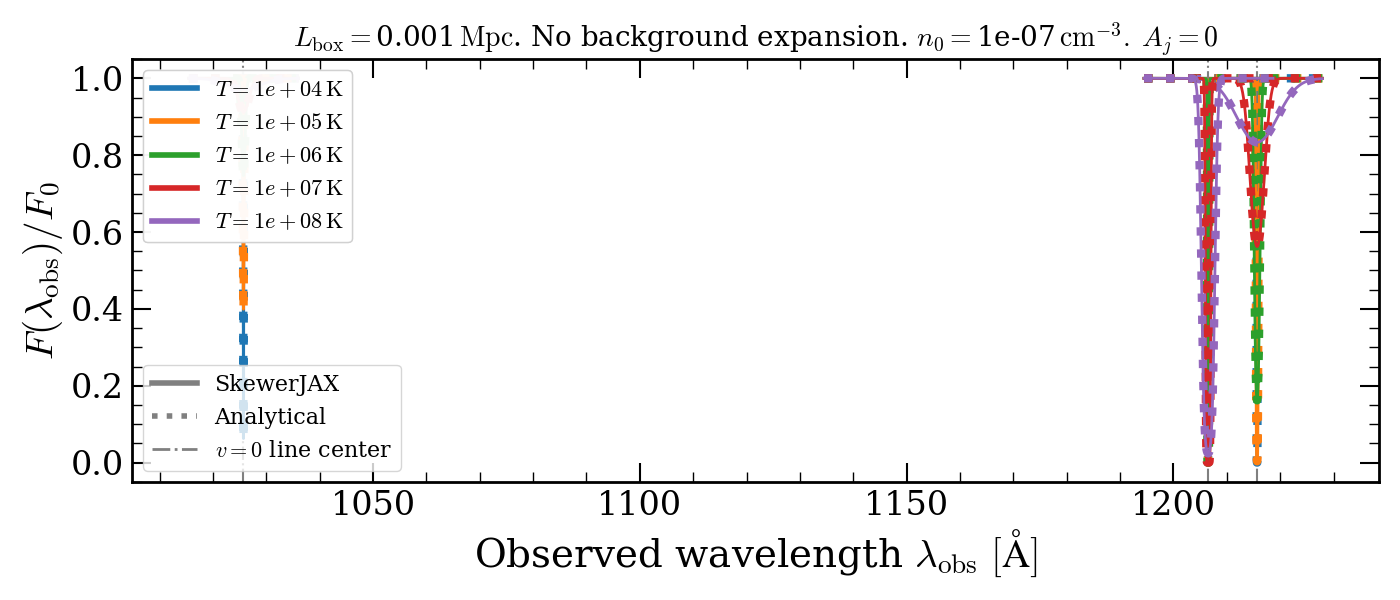

In [12]:
# Convert JAX arrays to NumPy for plotting

F_over_F0_np = np.asarray(F_over_F0)
F_over_F0_analytic_np = np.asarray(F_over_F0_analytic)

a_dagger_plot = float(jnp.asarray(a_dagger).reshape(-1)[0])
a_obs_plot = 1.0

wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
    velocities_kms,
    line_bundle_null,
    a_dagger=a_dagger_plot,
    a_obs=a_obs_plot,
)  # (N_lines, N_v)

wavelengths_per_line_np = np.asarray(wavelengths_per_line_A)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes, but using each line's own observed-wavelength grid

for i_sp, line in enumerate(line_bundle_null.lines):
    lambdas_np = wavelengths_per_line_np[i_sp]
    lambda_center_A = line.lambda0_A * a_obs_plot / a_dagger_plot

    ax.axvline(lambda_center_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)

    for i_sk in range(N_sk):
        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic_np[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=6.0)

ax.set_xlabel(r"Observed wavelength $\lambda_{\rm obs}\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda_{\rm obs}) / F_0$")
ax.set_title(
    r"$L_{\mathrm{box}} = $" + str(L_box_Kpc) + r"$\,\mathrm{Mpc}$"
    + ". No background expansion. "
    + r"$n_0 = $" + str(n0_ref) + r"$ \, \mathrm{cm^{-3}}.\;$"
    + r"$A_j = 0$",
    fontsize=20,
)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical'),
    Line2D([0], [0], color='grey', lw=2, linestyle='-.', label=r"$v=0$ line center"),
]
legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = []
for i_sk in range(N_sk):
    _sampled_T_K = sampled_temperatures_K[i_sk]
    _lbl = rf"$T = {_sampled_T_K:.2g} \, \mathrm{{K}}$"
    handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=_lbl))

leg = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(leg)

fig.tight_layout()
plt.show()

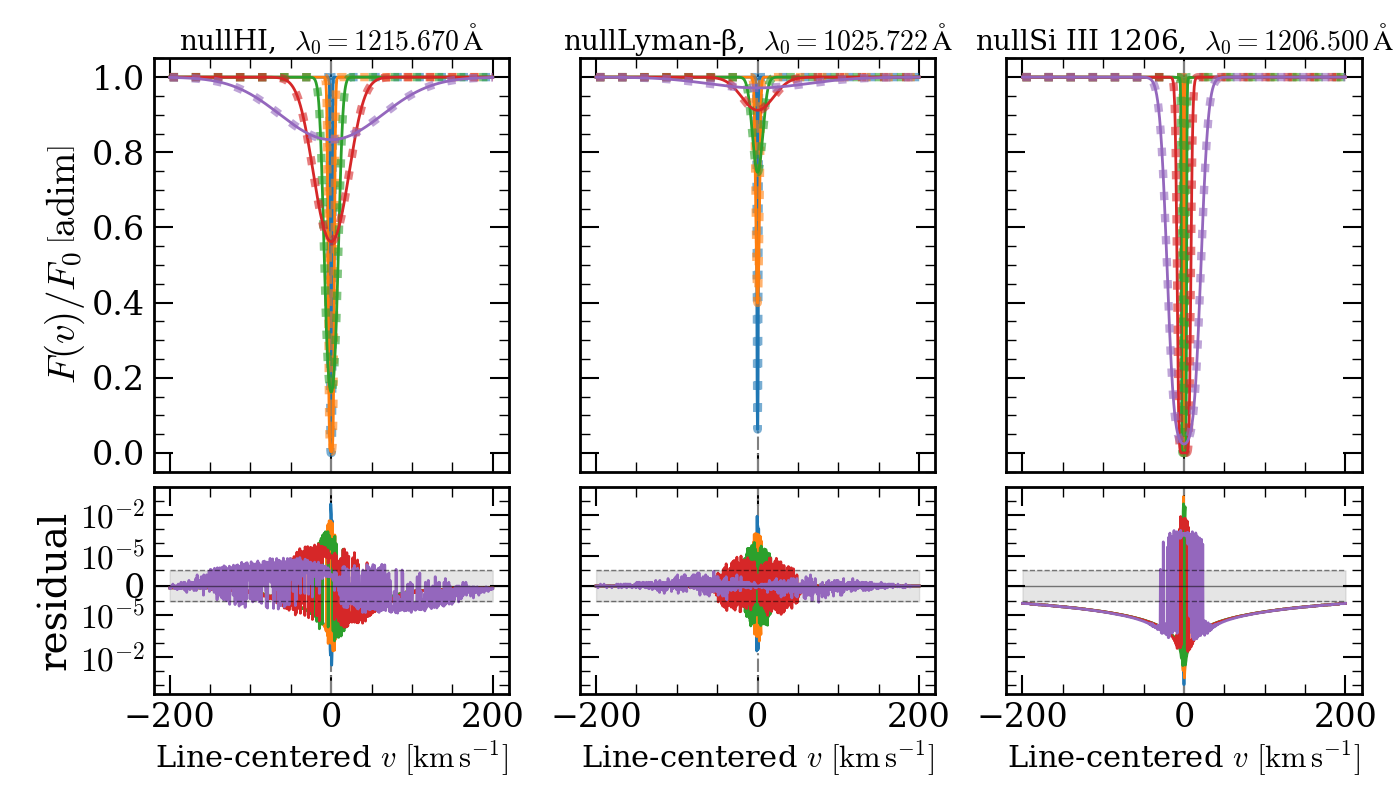

In [13]:
# Zoom half-width around each line center [km/s]
N_lines = line_bundle_null.n_lines

fig, axes = plt.subplots(nrows=2, ncols=N_lines, figsize=(14, 8), sharex='col', sharey='row', gridspec_kw=dict(height_ratios=[2, 1]))

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle_null.lines)):

    ax_main.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        ax_main.plot(velocities_np, F_over_F0_np[i_sp, i_sk], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(velocities_np, F_over_F0_analytic_np[i_sp, i_sk], color=colors[i_sk], linestyle=':', linewidth=6.0, alpha=0.6)

        residual = F_over_F0_np[i_sp, i_sk] / F_over_F0_analytic_np[i_sp, i_sk] - 1
        ax_res.plot(velocities_np, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)

    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(velocities_np, -1e-6, 1e-6, color="grey", alpha=0.2)
    ax_res.hlines(1e-6, xmin=velocities_np[0], xmax=velocities_np[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-6, xmin=velocities_np[0], xmax=velocities_np[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)

    ax_res.set_xlabel(r"Line-centered $v\ [\mathrm{km\,s^{-1}}]$", fontsize=22)
    ax_res.set_yscale("symlog", linthresh=1e-6)

    major_ticks = [-1e-2, -1e-5, 0.0, 1e-5, 1e-2]
    ax_res.set_yticks(major_ticks)
    ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

axes[0,0].set_ylabel(r"$F(v) / F_0\, \left[\mathrm{adim}\right]$")
axes[1,0].set_ylabel("residual")
    
fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)

plt.show()

# Numerical VS Analytical for a rad.-domination with $n=n_0, T=0$

In [14]:
# Define fields

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_five_Mpc)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),                     # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),   # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                               # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                             # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_tiny, T0_tiny, L_box_five_Mpc)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),                     # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),   # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                               # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                             # UNITS: [GHz]
    }
})

# Define skewers

N_sk = 2
N_ppsk = 128

_points = jnp.array([
    jnp.linspace(0.0, L_box_five_Mpc, N_ppsk),
    L_box_five_Mpc / 2 * jnp.ones(N_ppsk),
    L_box_five_Mpc / 2 * jnp.ones(N_ppsk),
]).T

_points = jnp.tile(_points[None, ...], (N_sk, 1, 1))

skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=[1.0, 0.99999976],
    x0=[0.0, 0.0],
    ICs_defined_at_index=[-1, 0],
    ICs_at_emission_or_absorption=["absorption", "emission"],
    cosmologies=cosmology,
)

2026-06-16 10:18:10,654 - INFO - Initializing SkewerBundle with 2 skewers, 128 points per skewer
2026-06-16 10:18:10,714 - INFO - Using per-skewer ICs_defined_at_index: [-1  0]
2026-06-16 10:18:10,715 - INFO - Using per-skewer emission/absorption flags
2026-06-16 10:18:10,775 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-16 10:18:11,039 - INFO - Computing comoving distances along skewer direction
2026-06-16 10:18:11,229 - INFO - Computing scale factors from cosmology
2026-06-16 10:18:12,229 - INFO - Storing quadri-vectors
2026-06-16 10:18:12,274 - INFO - SkewerBundle initialization complete


In [15]:
# Define velocity grid and a_dagger

quadri_vectors = skewer_bundle.quadri_vectors[ii_cosmology]  # (N_sk, N_ppsk, 4)

_indicies_final_array = jnp.where(skewer_bundle.ICs_defined_at_index == 0, -1, 0)
v_centers_kms = phys.c_kms * jnp.log(
    jnp.asarray(skewer_bundle.a0)
    /
    quadri_vectors[jnp.arange(N_sk), _indicies_final_array, 0]
)

delta_v_pad_kms = 200.0
velocities_kms = jnp.linspace(
    jnp.min(v_centers_kms) - delta_v_pad_kms,
    jnp.max(v_centers_kms) + delta_v_pad_kms,
    2048,
)

# Use a_dagger = a0 for each skewer, tiled along the skewer points.
a_dagger = jnp.repeat(jnp.asarray(skewer_bundle.a0)[:, None], N_ppsk, axis=1)

# Compute optical depth in velocity units

tau = od.OpticalDepthCalculator(
    skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
)
tau.compute()
optical_depth = tau.optical_depth

F_over_F0 = jnp.exp(-optical_depth)

2026-06-16 10:18:12,944 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=3, N_species=2, N_sk=2, N_ppsk=128, N_v=2048.
2026-06-16 10:18:12,944 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 1.526 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.2%
  System RAM  : used=24.197 GB, available=101.410 GB  [█████░░░░░░░░░░░░░░░░░░░░░░░]  19.3%
  Change      : ΔRSS=first checkpoint
2026-06-16 10:18:12,944 - INFO - [OPTICAL_DEPTH] start: ii_cosmology=0, voigt=ExoJAX
2026-06-16 10:18:12,945 - INFO - 
[OPTICAL_DEPTH][MEM] loaded quadri_vectors
  Process RSS : 1.526 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.2%
  System RAM  : used=24.197 GB, available=101.410 GB  [█████░░░░░░░░░░░░░░░░░░░░░░░]  19.3%
  Change      : ΔRSS=+0.000 GB
  Array       : shape=(2, 128, 4), dtype=float32, nbytes=0.000 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.0%
2026-06-16 10:18:14,231 - INFO - 
[OPTICAL_DEPTH][MEM] after compute_line_profiles
  Process RSS : 1.601 / 125.607 GB  [░░░░░░░░░░░░░

In [16]:
# Analytical result

xem_Mpc = jnp.array([-L_box_five_Mpc, 0.0])
xf_Mpc = jnp.array([0.0, L_box_five_Mpc])

# Since a_dagger = a_obs = a0 for each skewer, the wavelength mapping is simply:
# lambda_obs,j(v) = lambda_j exp(v/c)
wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
    velocities_kms, line_bundle, a_dagger=1.0, a_obs=1.0,
)  # (N_lines, N_v)

optical_depth_analytic_list = []

for i_line in range(line_bundle.n_lines):
    _tau_i = analytic_solutions.compute_optical_depth_analytical_radiation_domination_Natural(
        wavelengths_per_line_A[i_line],
        line_bundle.lambda0_A[i_line:i_line + 1],
        line_bundle.A21_GHz[i_line:i_line + 1],
        line_bundle.f_osc[i_line:i_line + 1],
        skewer_bundle.a0,
        skewer_bundle.x0,
        xem_Mpc=xem_Mpc,
        xf_Mpc=xf_Mpc,
        n0_cm3=jnp.array([n0_ref, n0_ref]),
    )  # (1, N_sk, N_v)

    optical_depth_analytic_list.append(_tau_i[0])

optical_depth_analytic = jnp.stack(optical_depth_analytic_list, axis=0)  # (N_lines, N_sk, N_v)
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

/home/dlopez/tmp/pip-tmp/ipykernel_464601/508174618.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


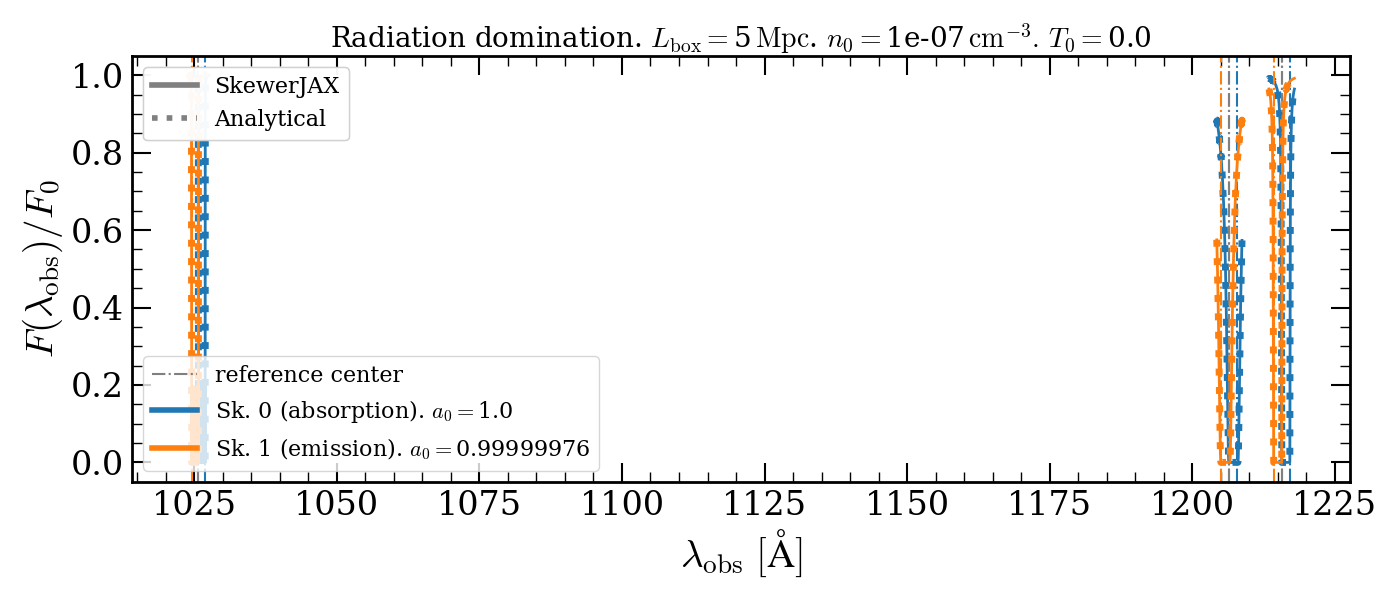

In [17]:
# Convert JAX arrays to NumPy for plotting

F_over_F0_np = np.asarray(F_over_F0)
F_over_F0_analytic_np = np.asarray(F_over_F0_analytic)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))
handles = [Line2D([0], [0], color='grey', lw=1.5, linestyle='-.', label=r'reference center')]
for i_sp, line in enumerate(line_bundle.lines):

    for i_sk in range(N_sk):
        _a_dagger = a_dagger[i_sk, 0]
        _a_obs = skewer_bundle.a0[i_sk]
        _af = quadri_vectors[i_sk, _indicies_final_array[i_sk], 0]
        _v_center = float(phys.c_kms * jnp.log(_a_dagger / _af))

        wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
            velocities_kms, line_bundle, a_dagger=_a_dagger, a_obs=_a_obs,
        )  # (N_lines, N_v)

        lambdas_np = np.asarray(wavelengths_per_line_A[i_sp])

        _lambda_ref = float(line.lambda0_A * _a_obs / _a_dagger)
        _lambda_center = float(line.lambda0_A * _a_obs / _af)

        ax.axvline(_lambda_ref, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
        ax.axvline(_lambda_center, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic_np[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=5.0)

        _emission_or_absorption = "absorption" if skewer_bundle.is_absorption[i_sk] else "emission"

        if i_sp == 0:
            handles.append(
                Line2D(
                    [0], [0], color=colors[i_sk], lw=4, linestyle='-',
                    label="Sk. " + str(i_sk) + " (" + _emission_or_absorption + r"). $a_0 = $" + str(skewer_bundle.a0[i_sk])
                )
            )

legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical'),
]
legend = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(legend)

ax.set_xlabel(r"$\lambda_{\rm obs}\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda_{\rm obs}) / F_0$")
ax.set_title(
    r"Radiation domination. $L_{\mathrm{box}} = $" + str(L_box_five_Mpc)
    + r"$\,\mathrm{Mpc}$. $n_0 = $" + str(n0_ref)
    + r"$\,\mathrm{cm}^{-3}.\, T_0 = $" + str(round(T0_tiny, 4)),
    fontsize=20,
)

fig.tight_layout()
plt.show()

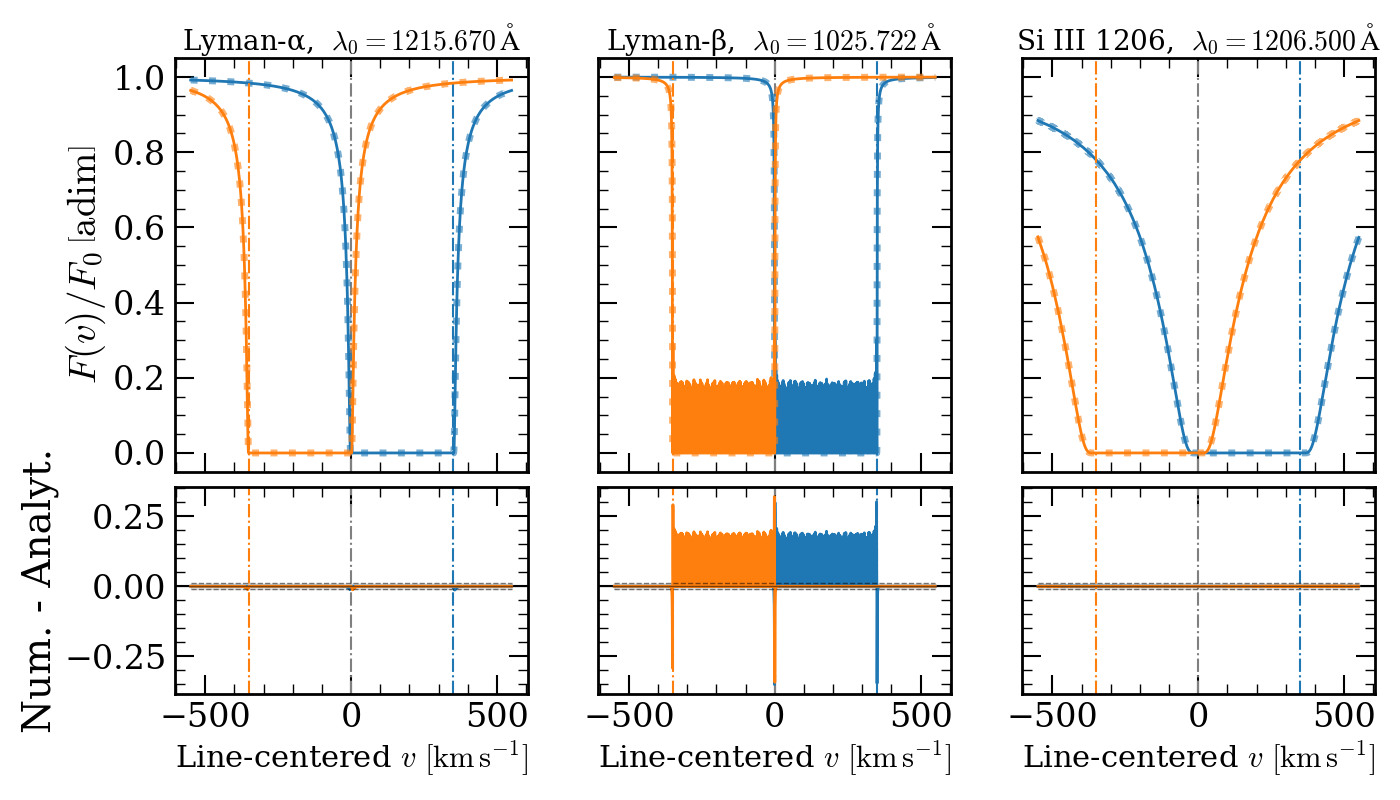

In [18]:
# Zoom half-width around each line center [km/s]
N_lines = line_bundle.n_lines

fig, axes = plt.subplots(nrows=2, ncols=N_lines, figsize=(14, 8), sharex='col', sharey='row', gridspec_kw=dict(height_ratios=[2, 1]))

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):

    ax_main.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        _a_dagger = a_dagger[i_sk, 0]
        _af = quadri_vectors[i_sk, _indicies_final_array[i_sk], 0]
        _v_center = float(phys.c_kms * jnp.log(_a_dagger / _af))

        ax_main.axvline(_v_center, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)
        ax_res.axvline(_v_center, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax_main.plot(velocities_kms, F_over_F0_np[i_sp, i_sk], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(velocities_kms, F_over_F0_analytic_np[i_sp, i_sk], color=colors[i_sk], linestyle=':', linewidth=5.0, alpha=0.6)

        residual = F_over_F0_np[i_sp, i_sk] - F_over_F0_analytic_np[i_sp, i_sk]
        ax_res.plot(velocities_kms, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)

    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(velocities_kms, -1e-2, 1e-2, color="grey", alpha=0.2)
    ax_res.hlines(1e-2, xmin=velocities_kms[0], xmax=velocities_kms[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-2, xmin=velocities_kms[0], xmax=velocities_kms[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)

    ax_res.set_xlabel(r"Line-centered $v\ [\mathrm{km\,s^{-1}}]$", fontsize=22)
    
axes[0,0].set_ylabel(r"$F(v) / F_0\, \left[\mathrm{adim}\right]$")
axes[1,0].set_ylabel("Num. - Analyt.")

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)

plt.show()

# Numerical VS Analytical for a rad.-domination with $n=n_0,\, A_{21} = 0, T=T_0$

In [19]:
n0_ref = 5e-11

T0_min = 5e4
T0_max = 5e6

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_five_Mpc)),        # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),                    # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),  # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                              # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                            # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min, T0_max, L_box_five_Mpc)),        # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box_five_Mpc)),                    # UNITS: [km/s]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_ref, n0_ref, L_box_five_Mpc)),  # UNITS: [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                              # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                            # UNITS: [GHz]
    },
})

N_sk = 2
N_ppsk = 42

_points = aux.make_plane_points(L_box_five_Mpc, 'y', L_box_five_Mpc/2, N_sk, N_ppsk)

skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=[1.0, 0.99999976],
    x0=[0.0, 0.0],
    ICs_defined_at_index=[-1, 0],
    ICs_at_emission_or_absorption=["absorption", "emission"],
    cosmologies=cosmology,
)

velocities_kms = jnp.linspace(-4000.0, 4000.0, 1024)

a_dagger = jnp.repeat(jnp.asarray(skewer_bundle.a0)[:, None], skewer_bundle.N_ppsk, axis=1)

tau = od.OpticalDepthCalculator(
    skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
)
tau.compute()
optical_depth = tau.optical_depth
F_over_F0 = jnp.exp(-optical_depth)

2026-06-16 10:18:17,603 - INFO - Initializing SkewerBundle with 2 skewers, 42 points per skewer
2026-06-16 10:18:17,605 - INFO - Using per-skewer ICs_defined_at_index: [-1  0]
2026-06-16 10:18:17,605 - INFO - Using per-skewer emission/absorption flags
2026-06-16 10:18:17,606 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-16 10:18:17,815 - INFO - Computing comoving distances along skewer direction
2026-06-16 10:18:17,975 - INFO - Computing scale factors from cosmology
2026-06-16 10:18:18,872 - INFO - Storing quadri-vectors
2026-06-16 10:18:18,921 - INFO - SkewerBundle initialization complete
2026-06-16 10:18:18,949 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=3, N_species=2, N_sk=2, N_ppsk=42, N_v=1024.
2026-06-16 10:18:18,949 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 1.768 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.4%
  System RAM  : used=24.453 GB, available=101.154 GB  [█████░░░░░░░░░░░░░░░░░░░░░░░] 

In [20]:
# Analytical result in velocity units

xem_Mpc = jnp.array([-L_box_five_Mpc, 0.0])
xf_Mpc = jnp.array([0.0, L_box_five_Mpc])

_T0 = jnp.array([T0_min, T0_max])

wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
    velocities_kms,
    line_bundle_null,
    a_dagger=1.0,
    a_obs=1.0,
)  # (N_lines, N_v)

optical_depth_analytic_list = []

for i_line in range(line_bundle_null.n_lines):
    _tau_i = analytic_solutions.compute_optical_depth_analytical_radiation_domination_Thermal(
        wavelengths_per_line_A[i_line],
        line_bundle_null.lambda0_A[i_line:i_line + 1],
        line_bundle_null.f_osc[i_line:i_line + 1],
        line_bundle_null.mass_amu[i_line:i_line + 1],
        _T0,
        skewer_bundle.a0,
        skewer_bundle.x0,
        xem_Mpc=xem_Mpc,
        xf_Mpc=xf_Mpc,
        n0_cm3=jnp.array([n0_ref, n0_ref]),
    )  # (1, N_sk, N_v)

    optical_depth_analytic_list.append(_tau_i[0])

optical_depth_analytic = jnp.stack(optical_depth_analytic_list, axis=0)  # (N_lines, N_sk, N_v)
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

/home/dlopez/tmp/pip-tmp/ipykernel_464601/3739910826.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


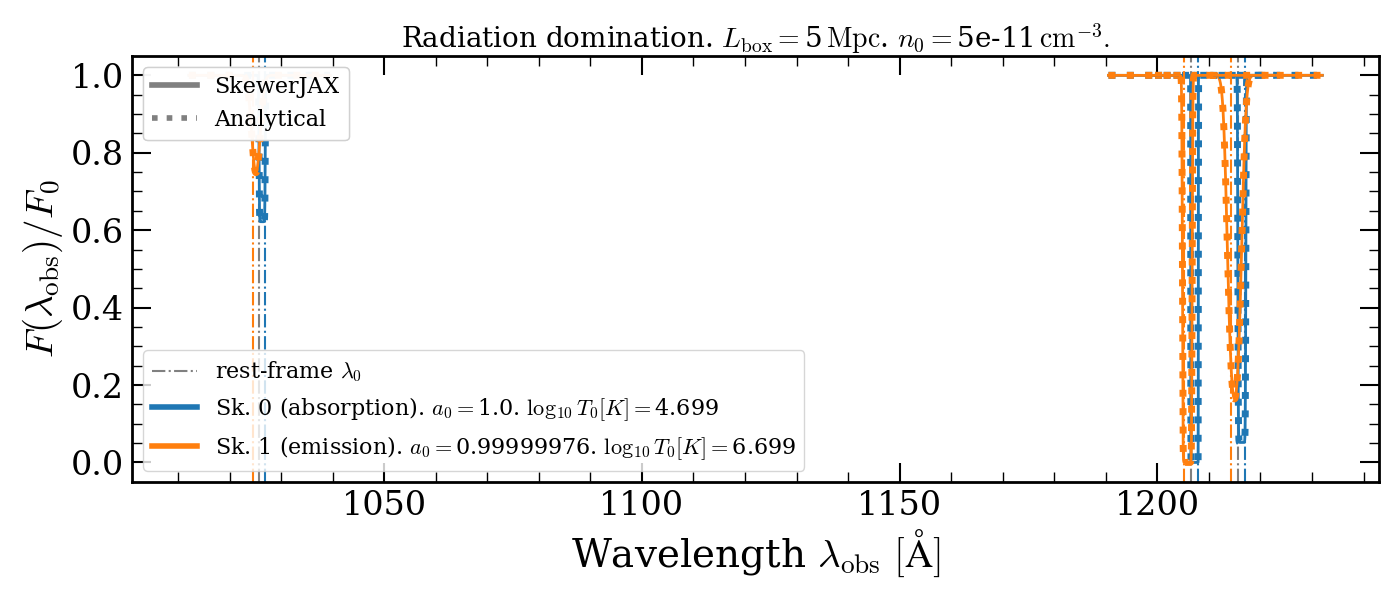

In [21]:
# Convert JAX arrays to NumPy for plotting

F_over_F0_np = np.asarray(F_over_F0)
F_over_F0_analytic_np = np.asarray(F_over_F0_analytic)

_indicies_final_array = jnp.where(skewer_bundle.ICs_defined_at_index == 0, -1, 0)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

handles = [Line2D([0], [0], color='grey', lw=1.5, linestyle='-.', label=r'rest-frame $\lambda_0$')]

for i_sp, line in enumerate(line_bundle_null.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)

    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]

        wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(
            velocities_kms, line_bundle_null, a_dagger=_a0, a_obs=_a0,
        )  # (N_lines, N_v)

        lambdas_np = np.asarray(wavelengths_per_line_A[i_sp])

        _lambda_final = line.lambda0_A * _a0 / _af
        ax.axvline(_lambda_final, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic_np[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=5.0)

        _emission_or_absorption = "absorption" if skewer_bundle.is_absorption[i_sk] else "emission"
        if i_sp == 0:
            handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle='-',
                label="Sk. " + str(i_sk) + " (" + _emission_or_absorption + r"). $a_0 = $" + str(skewer_bundle.a0[i_sk]) + r". $\log_{10}T_0 [K]= $" + str(round(jnp.log10(_T0[i_sk]), 4)))
            )

legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical'),
]
legend = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(legend)

ax.set_xlabel(r"Wavelength $\lambda_{\rm obs}\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda_{\rm obs}) / F_0$")
ax.set_title(
    r"Radiation domination. $L_{\mathrm{box}} = $" + str(L_box_five_Mpc) + r"$\,\mathrm{Mpc}$. $n_0 = $" + str(n0_ref) + r"$\,\mathrm{cm}^{-3}.$",
    fontsize=20,
)

fig.tight_layout()
plt.show()

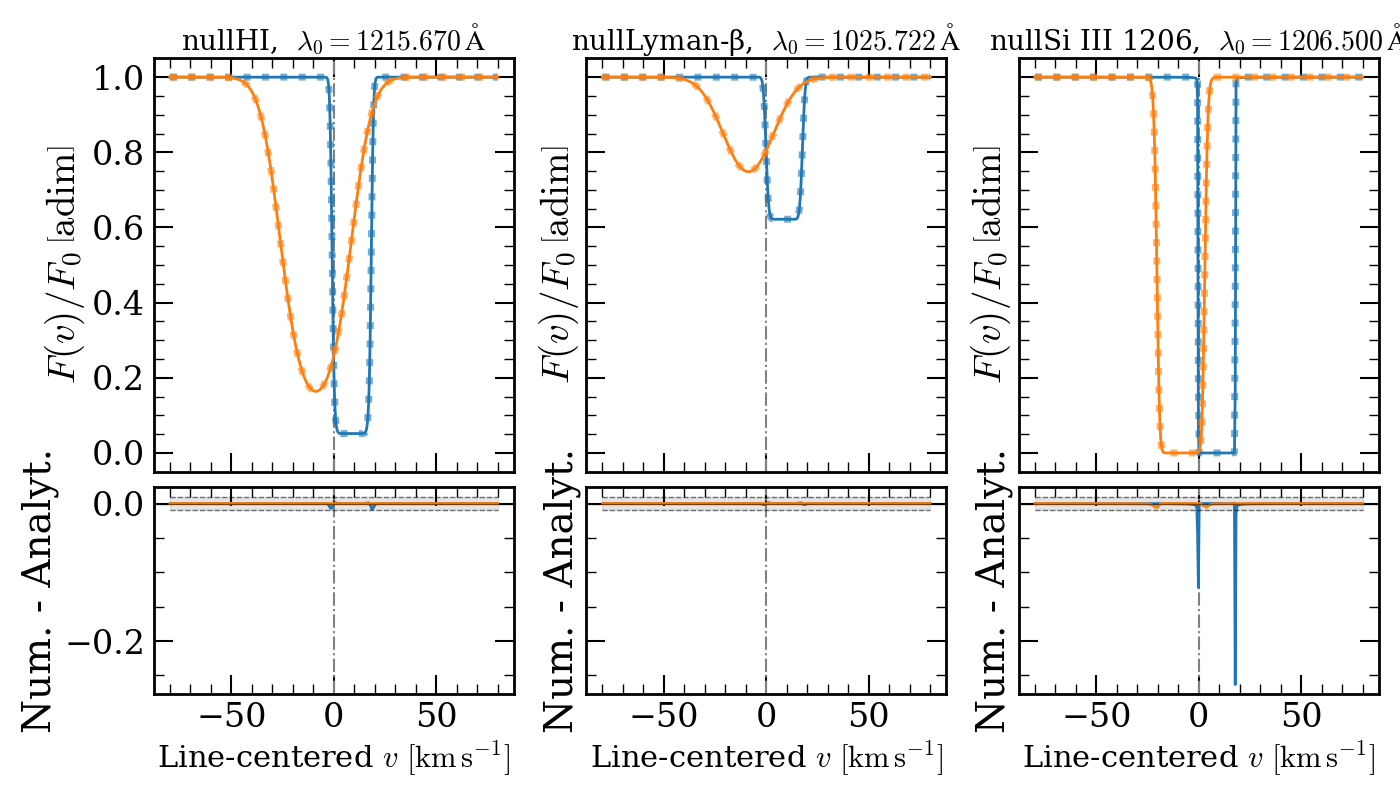

In [22]:
# Zoom half-width around each line center [km/s]

delta_v_kms = 80.0
N_lines = line_bundle_null.n_lines

fig, axes = plt.subplots(
    nrows=2,
    ncols=N_lines,
    figsize=(14, 8),
    sharex='col',
    sharey='row',
    gridspec_kw=dict(height_ratios=[2, 1]),
)

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle_null.lines)):
    mask = (velocities_np >= -delta_v_kms) & (velocities_np <= delta_v_kms)
    v_win = velocities_np[mask]

    ax_main.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]

        ax_main.plot(v_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(v_win, F_over_F0_analytic_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=5.0, alpha=0.6)

        residual = F_over_F0_np[i_sp, i_sk, mask] - F_over_F0_analytic_np[i_sp, i_sk, mask]
        ax_res.plot(v_win, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(v) / F_0\, \left[\mathrm{adim}\right]$")

    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(v_win, -1e-2, 1e-2, color="grey", alpha=0.2)
    ax_res.hlines(1e-2, xmin=v_win[0], xmax=v_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-2, xmin=v_win[0], xmax=v_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)

    ax_res.set_xlabel(r"Line-centered $v\ [\mathrm{km\,s^{-1}}]$", fontsize=22)
    ax_res.set_ylabel("Num. - Analyt.")

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)
plt.show()